# Task 3 — Customer Segmentation Using RFM and K-Means

QSkill Internship | Domain: Data Science | Slab 1: Beginners

## 1. Objective
Use transaction data to calculate customer-level Recency, Frequency, and Monetary (RFM) values, cluster customers using K-Means, visualize groups, and suggest practical marketing actions. The dataset is synthetic and reproducible.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n_customers = 320
n_orders = 2400
customer_ids = rng.integers(10000, 10000+n_customers, n_orders)
dates = pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n_orders), unit="D")
quantities = rng.integers(1, 8, n_orders)
prices = rng.choice([8, 15, 25, 40, 65, 100, 150], n_orders, p=[.16,.18,.20,.17,.13,.10,.06])
transactions = pd.DataFrame({"Invoice": [f"INV{i:06d}" for i in range(n_orders)],
                             "CustomerID":customer_ids, "InvoiceDate":dates,
                             "Quantity":quantities, "UnitPrice":prices})
transactions["Amount"] = transactions["Quantity"] * transactions["UnitPrice"]
transactions.loc[3, "Quantity"] = np.nan
transactions = pd.concat([transactions, transactions.iloc[[7]]], ignore_index=True)
transactions.head()

,Invoice,CustomerID,InvoiceDate,Quantity,UnitPrice,Amount
0,INV000000,10028,2025-01-03,5.0,15,75
1,INV000001,10247,2025-07-26,5.0,8,40
2,INV000002,10209,2025-09-30,2.0,25,50
3,INV000003,10140,2025-07-21,NaN,15,90
4,INV000004,10138,2025-05-21,5.0,100,500


## 2. Clean data and calculate RFM

In [3]:
print("Shape before cleaning:", transactions.shape)
print("Missing values:\n", transactions.isna().sum())
print("Duplicates:", transactions.duplicated().sum())
transactions = transactions.drop_duplicates().copy()
transactions["Quantity"] = pd.to_numeric(transactions["Quantity"], errors="coerce")
transactions["UnitPrice"] = pd.to_numeric(transactions["UnitPrice"], errors="coerce")
transactions["Quantity"] = transactions["Quantity"].fillna(transactions["Quantity"].median())
transactions = transactions[(transactions["Quantity"] > 0) & (transactions["UnitPrice"] > 0)]
transactions["Amount"] = transactions["Quantity"] * transactions["UnitPrice"]
snapshot_date = transactions["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = transactions.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Amount", "sum")
).reset_index()
display(rfm.head())
display(rfm[["Recency","Frequency","Monetary"]].describe().round(2))

Shape before cleaning: (2401, 6)
Missing values:
 Invoice        0
CustomerID     0
InvoiceDate    0
Quantity       1
UnitPrice      0
Amount         0
dtype: int64
Duplicates: 1


,CustomerID,Recency,Frequency,Monetary
0,10000,86,8,1085.0
1,10001,44,10,693.0
2,10002,18,10,1429.0
3,10003,29,6,727.0
4,10004,43,4,145.0


,Recency,Frequency,Monetary
count,319.00,319.00,319.00
mean,48.27,7.52,1218.11
std,52.24,2.82,676.82
min,1.00,1.00,15.00
25%,12.00,6.00,710.00
50%,30.00,7.00,1145.00
75%,63.00,9.00,1576.50
max,359.00,16.00,3555.00


## 3. Explore customer purchasing behavior

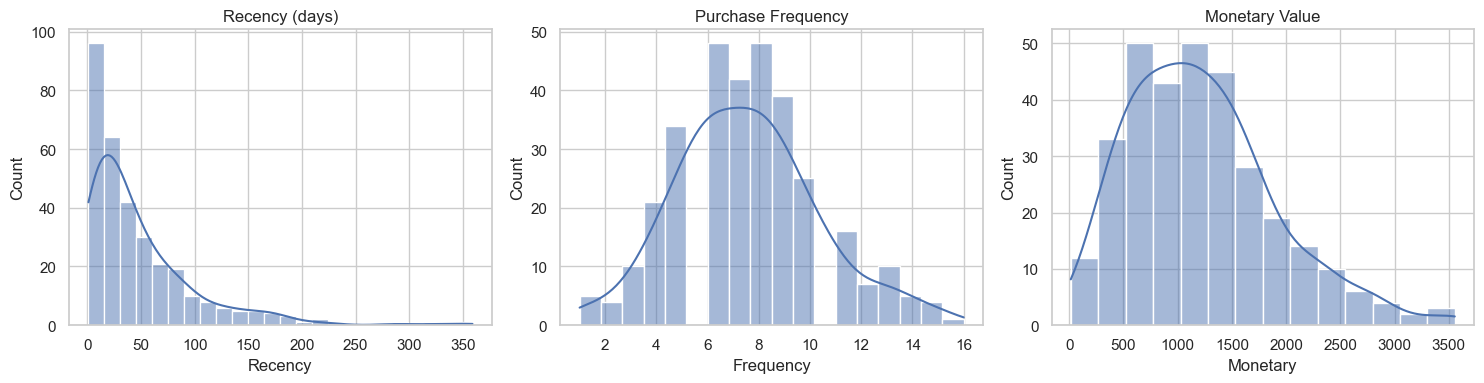

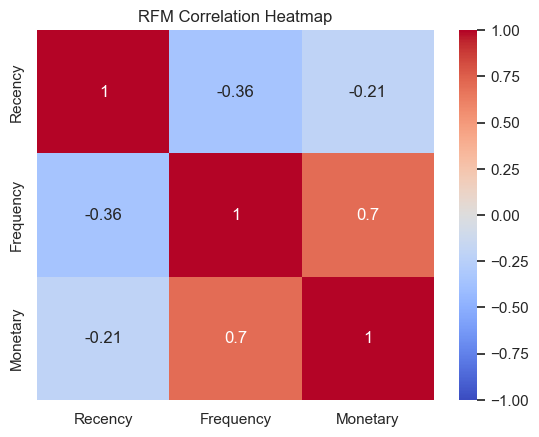

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
sns.histplot(rfm["Recency"], kde=True, ax=axes[0]); axes[0].set_title("Recency (days)")
sns.histplot(rfm["Frequency"], kde=True, ax=axes[1]); axes[1].set_title("Purchase Frequency")
sns.histplot(rfm["Monetary"], kde=True, ax=axes[2]); axes[2].set_title("Monetary Value")
plt.tight_layout()
plt.show()
sns.heatmap(rfm[["Recency","Frequency","Monetary"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("RFM Correlation Heatmap")
plt.show()

## 4. Scale features and choose K using elbow and silhouette

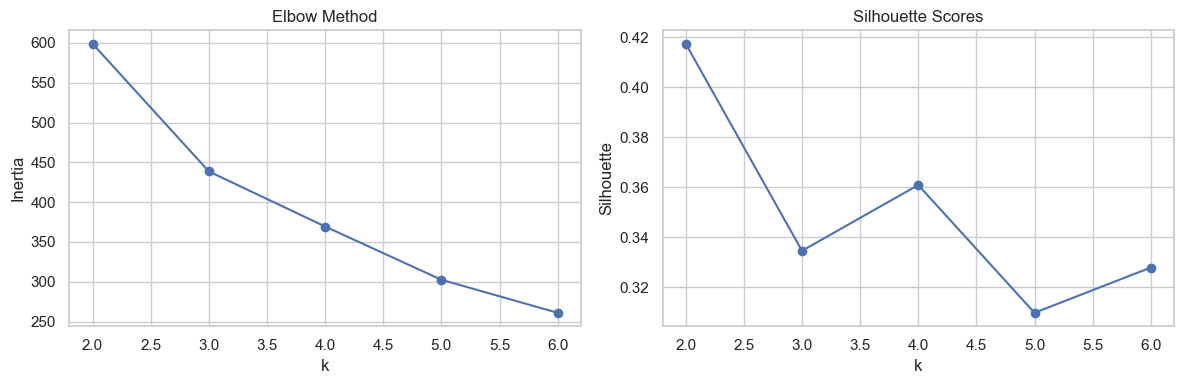

Selected k by highest silhouette score: 2


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline

features = rfm[["Recency","Frequency","Monetary"]].copy()
# Log transform reduces the skew of frequency and spend before scaling.
features["Frequency"] = np.log1p(features["Frequency"])
features["Monetary"] = np.log1p(features["Monetary"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)
inertias, silhouettes = [], []
k_values = range(2, 7)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(list(k_values), inertias, marker="o"); axes[0].set_title("Elbow Method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o"); axes[1].set_title("Silhouette Scores"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()
best_k = list(k_values)[int(np.argmax(silhouettes))]
print("Selected k by highest silhouette score:", best_k)
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

## 5. Interpret clusters and recommend actions

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,82,85.99,4.39,565.62
1,237,35.22,8.61,1443.86


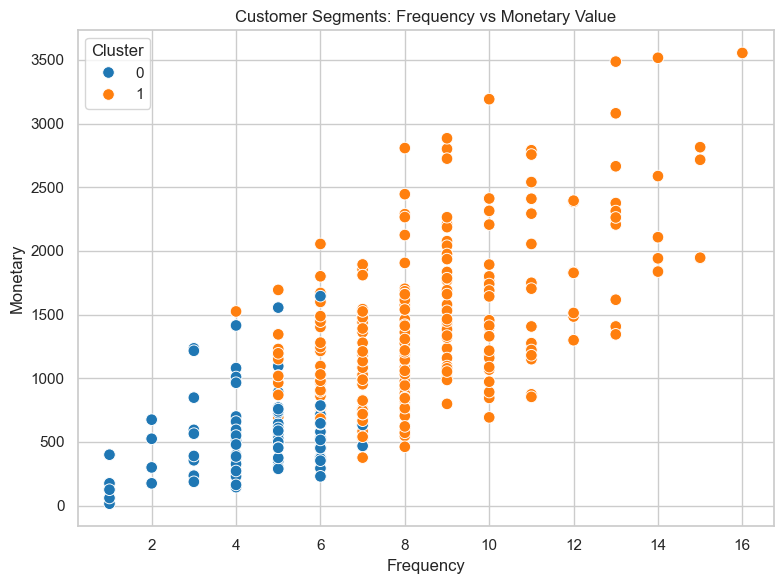

In [6]:
segment_summary = rfm.groupby("Cluster").agg(
    Customers=("CustomerID","count"),
    Avg_Recency=("Recency","mean"),
    Avg_Frequency=("Frequency","mean"),
    Avg_Monetary=("Monetary","mean")
).round(2)
display(segment_summary)
plt.figure(figsize=(8,6))
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Cluster", palette="tab10", s=70)
plt.title("Customer Segments: Frequency vs Monetary Value")
plt.tight_layout()
plt.show()

In [7]:
overall_monetary = rfm.groupby("Cluster")["Monetary"].mean()
overall_frequency = rfm.groupby("Cluster")["Frequency"].mean()
overall_recency = rfm.groupby("Cluster")["Recency"].mean()
for cluster in segment_summary.index:
    r = overall_recency[cluster]
    f = overall_frequency[cluster]
    m = overall_monetary[cluster]
    if r <= rfm["Recency"].median() and f >= rfm["Frequency"].median() and m >= rfm["Monetary"].median():
        label, action = "Loyal / high value", "Reward loyalty, offer early access, and protect retention."
    elif r > rfm["Recency"].median():
        label, action = "At-risk / inactive", "Send win-back campaigns and personalized incentives."
    elif f < rfm["Frequency"].median():
        label, action = "New / occasional", "Use onboarding, bundles, and next-purchase reminders."
    else:
        label, action = "Regular customers", "Encourage repeat purchases through cross-sells and membership benefits."
    print(f"Cluster {cluster} — {label}: {action}")
print("\nConclusion: cluster numbers are arbitrary; use the RFM averages to interpret each group rather than treating a cluster ID as a ranking.")

Cluster 0 — At-risk / inactive: Send win-back campaigns and personalized incentives.
Cluster 1 — At-risk / inactive: Send win-back campaigns and personalized incentives.

Conclusion: cluster numbers are arbitrary; use the RFM averages to interpret each group rather than treating a cluster ID as a ranking.
